In [16]:
import seaborn

from astropy import units
from astropy.time import Time

from selflensing.generators import RVGenerator, LightcurveGenerator
from selflensing.fitting import self_lensing_system_from_fit

from realistic import load_realistic_timeseries
from utils import DEFAULTS, default_rv_times

In [17]:
rts = load_realistic_timeseries()

In [18]:
# rts = rts[(rts['Porb'] > 60) & (rts['Porb'] < 150)]
len(rts)

516000

In [19]:
idx = 76
ts = rts.iloc[idx]
ts

a                                                                0.1
e                                                                0.0
periapsis_phase                                             1.570796
Macc                                                            20.0
Porb                                                        2.520512
Mcomp                                                            1.0
Rcomp                                                            1.0
b                                                                0.0
rv                 [-1128340.1983231881, 1474346.8345904374, -173...
rv_times           [2460676.5, 2460680.1868686867, 2460683.873737...
lc                 [0.9723954222380371, 1.0280591391394036, 0.977...
lc_times           [2460310.5, 2460314.196969697, 2460317.8939393...
peak_time                                                  2460462.5
rv_err                                                     10.046935
RV accuracy                       

<Axes: xlabel='rv_times', ylabel='rv'>

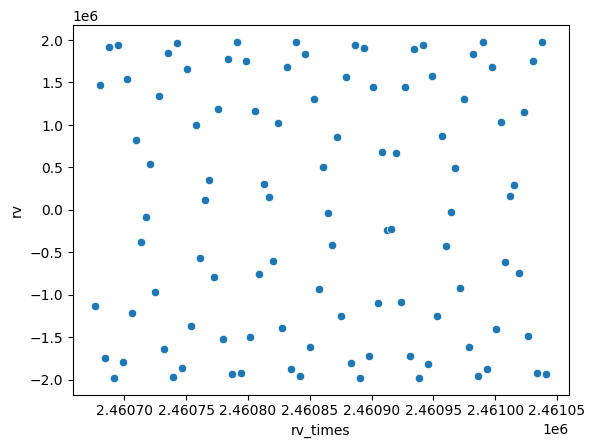

In [20]:
seaborn.scatterplot(ts.to_dict(), x='rv_times', y='rv')

<Axes: xlabel='lc_times', ylabel='lc'>

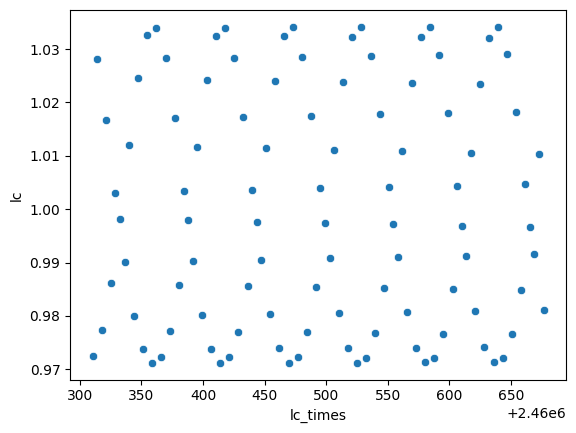

In [21]:
seaborn.scatterplot(ts.to_dict(), x='lc_times', y='lc')

In [22]:
from selflensing.lombscargle import get_periods

get_periods(ts['lc'], ts['lc_times'])

array([8.02631579, 7.99126638, 7.95652174, 7.92207792, 7.88793103,
       7.85407725, 7.82051282, 7.01149425, 6.98473282, 6.9581749 ,
       6.93181818, 6.90566038, 6.87969925, 6.85393258, 2.53112033,
       2.52762431, 2.52413793, 2.52066116, 2.51719395, 2.51373626,
       2.51028807, 2.42063492, 2.41743725, 2.41424802, 2.41106719,
       2.40789474, 2.40473062, 2.4015748 ])

In [23]:
sls, sampler = self_lensing_system_from_fit(
    rv_times=Time(ts['rv_times'], format='jd'),
    observed_rv=ts['rv'] * units.m / units.s,
    observed_rv_err=ts['rv_err'] * units.m / units.s,
    lc_times=Time(ts['lc_times'], format='jd'),
    observed_lc=ts['lc'] * units.dimensionless_unscaled,
    observed_lc_err=1 * units.dimensionless_unscaled,
    peak_time=Time(ts['peak_time'], format='jd'),
    Mcomp=DEFAULTS['Mcomp'],
    Rcomp=DEFAULTS['Rcomp'],
    Teff=DEFAULTS['Teff'],
    nsteps=2000,
    nwalkers=50,
    burn=300,
)

  0%|          | 0/2000 [00:00<?, ?it/s]/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 2000/2000 [00:33<00:00, 59.07it/s]


In [24]:
import numpy
numpy.median(sampler.get_chain(flat=True, discard=100), axis=0)

array([0.96358446, 0.40993599, 0.35336681, 4.63566477])

In [25]:
# sls.a = 1 * units.AU
rvg = RVGenerator(sls, Time(ts['rv_times'], format='jd'), Time(ts['peak_time'], format='jd'))

In [26]:
sls.a, sls.Macc, sls.e, sls.periapsis_phase, sls.porb

(<Quantity 0.01012427 AU>,
 <Quantity 1.7844773 solMass>,
 <Quantity 0.39266501>,
 <Quantity 3.79132913 rad>,
 <Quantity 0.22298323 d>)

<Axes: xlabel='rv_times', ylabel='rv'>

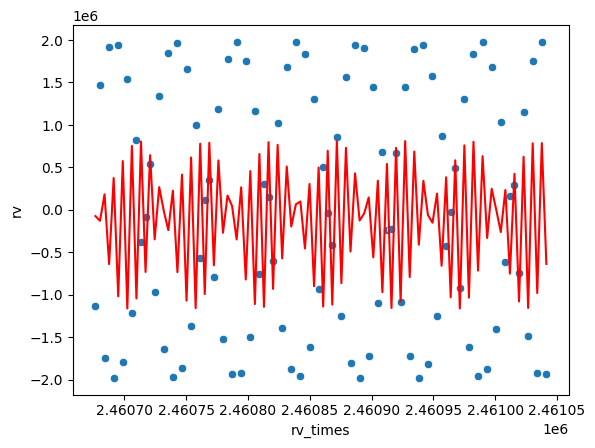

In [27]:
seaborn.scatterplot(ts.to_dict(), x='rv_times', y='rv')
seaborn.lineplot({'times': ts['rv_times'], 'rv': rvg.rv}, x='times', y='rv', color='red')

<Axes: xlabel='lc_times', ylabel='lc'>

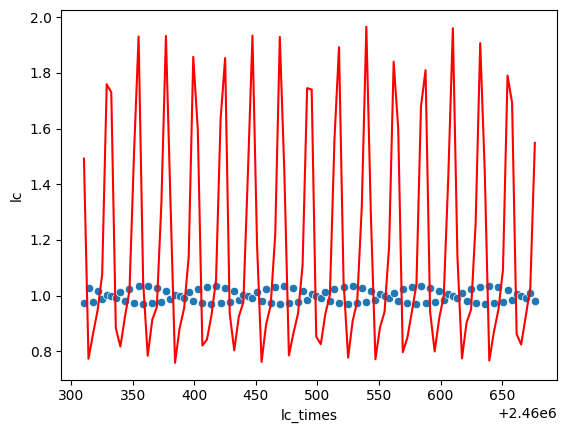

In [28]:
lcg = LightcurveGenerator(lensing_system=sls, times=Time(ts['lc_times'], format='jd'), peak_time=Time(ts['peak_time'], format='jd'))


seaborn.scatterplot(ts.to_dict(), x='lc_times', y='lc')
seaborn.lineplot({'times': ts['lc_times'], 'lc': lcg.flux_array}, x='times', y='lc', color='red')

Text(0.5, 0, 'step number')

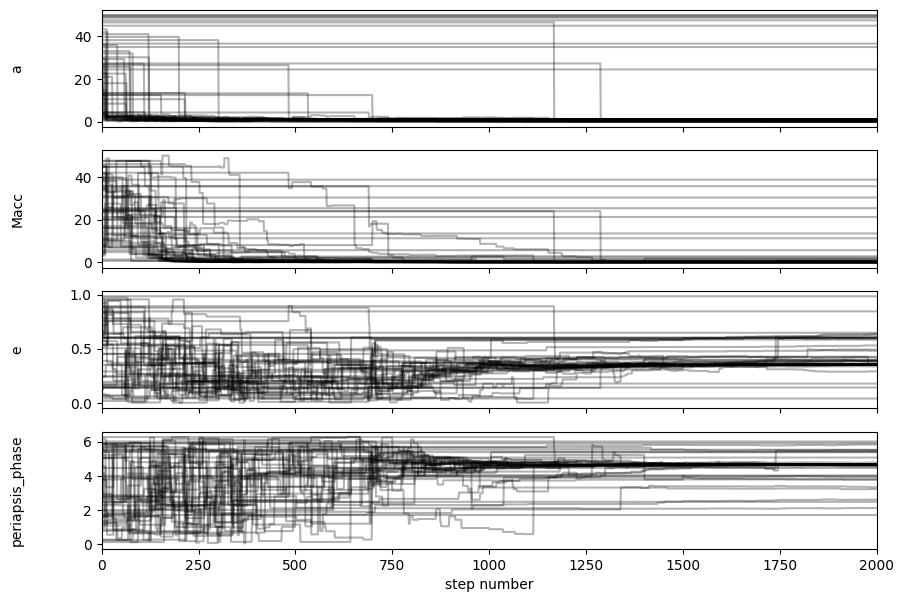

In [29]:
from matplotlib import pyplot as plt
labels = ["a", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain()#discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")

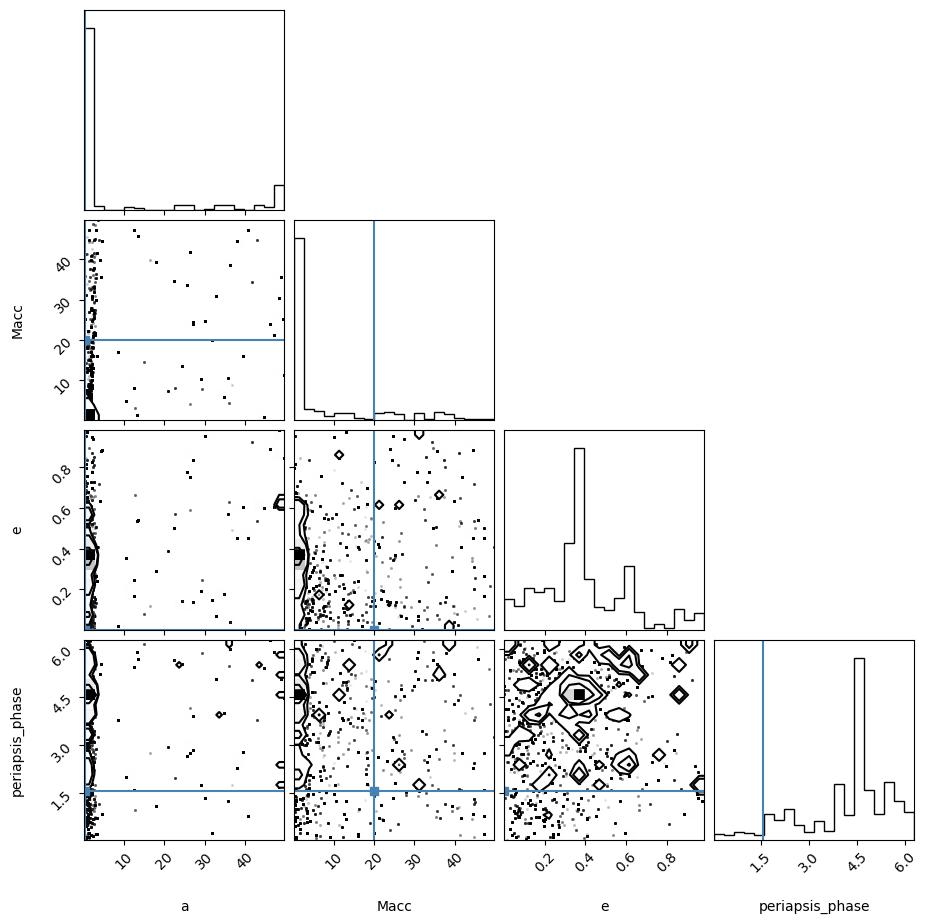

In [30]:
import corner

fig = corner.corner(
    flat_samples, labels=labels, truths=[ts['a'], ts['Macc'], ts['e'], ts['periapsis_phase']]
)